### scipy: Stochastik - Übungen

In diesem Notebook rechnest du **Stochastik** mit dem Modul `scipy.stats`: Wahrscheinlichkeiten der Binomialverteilung,
der hypergeometrischen Verteilung und der Normalverteilung, Zufallszahlen aus diesen Verteilungen und **Hypothesentests**:
den Binomialtest aus dem Mathematikunterricht, den **t-Test** zum Vergleich von Mittelwerten und den **Chi-Quadrat-Test**
zum Vergleich von Häufigkeiten.

Die Reihe hat vier Notebooks:

1. Analysis: Nullstellen, Gleichungen, Extremstellen, Integrale
2. Messdaten auswerten: Interpolation, Ausgleichskurven, Spitzen finden
3. **Stochastik**: Verteilungen und Hypothesentests (dieses Notebook)
4. Anwendungen: Änderungsraten und Modelle, lineare Optimierung, Abstände

Vorausgesetzt werden *numpy: Zufall und Statistik* und *matplotlib: Grundlagen*. Aus *scipy: Analysis* wird nur `optimize.brentq()` gebraucht.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Beim ersten `import scipy` lädt der Browser das Paket nach. Das dauert ein paar Sekunden.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

## 1. Die Binomialverteilung

#### Wahrscheinlichkeiten mit `stats.binom`

Ein Zufallsversuch mit zwei Ausgängen (Treffer oder Niete) wird `n`-mal unabhängig wiederholt, die **Trefferwahrscheinlichkeit** ist jedes Mal `p`
(eine **Bernoulli-Kette**). Die Anzahl `X` der Treffer ist dann **binomialverteilt**. Das Modul `scipy.stats` enthält dafür `stats.binom`:

| Aufruf | Bedeutung |
|---|---|
| `stats.binom.pmf(k, n, p)` | `P(X = k)`, genau `k` Treffer (*probability mass function*) |
| `stats.binom.cdf(k, n, p)` | `P(X ≤ k)`, höchstens `k` Treffer (*cumulative distribution function*) |
| `stats.binom.sf(k, n, p)` | `P(X > k)`, mehr als `k` Treffer (*survival function*, also `1 - cdf`) |

Für `k` darf auch ein Array stehen, dann erhält man alle Wahrscheinlichkeiten auf einmal.

In [ ]:
import numpy as np
from scipy import stats

n = 10
p = 1 / 6       # Anzahl der Sechsen bei 10 Würfen
print(f'{stats.binom.pmf(2, n, p):.4f}')
print(f'{stats.binom.cdf(2, n, p):.4f}')
print(f'{stats.binom.sf(2, n, p):.4f}')
print(np.round(stats.binom.pmf(np.arange(4), n, p), 4))

#### Mindestens, höchstens, zwischen

Alle anderen Fragen führt man auf `cdf` und `sf` zurück:

| Frage | Rechnung |
|---|---|
| höchstens `k` | `cdf(k, n, p)` |
| weniger als `k` | `cdf(k - 1, n, p)` |
| mindestens `k` | `sf(k - 1, n, p)` (oder `1 - cdf(k - 1, n, p)`) |
| mehr als `k` | `sf(k, n, p)` |
| von `a` bis `b` | `cdf(b, n, p) - cdf(a - 1, n, p)` |

Vorsicht bei „mindestens“: Wer mindestens 3 Treffer will, darf 0, 1 und 2 **nicht** abziehen, also `sf(2, ...)`.

In [ ]:
from scipy import stats

n, p = 20, 0.3
print(f'mindestens 5: {stats.binom.sf(4, n, p):.4f}')
print(f'weniger als 5: {stats.binom.cdf(4, n, p):.4f}')
print(f'von 4 bis 8: {stats.binom.cdf(8, n, p) - stats.binom.cdf(3, n, p):.4f}')

#### Erwartungswert und Standardabweichung

`stats.binom.mean(n, p)` ist der **Erwartungswert** `μ = n · p`, `stats.binom.std(n, p)` die **Standardabweichung** `σ = √(n · p · (1 - p))`.
Die Verteilung zeichnet man als Säulendiagramm mit `plt.bar(k, wahrscheinlichkeiten)` (aus *matplotlib: Diagrammtypen*).

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

n, p = 20, 0.3
print(f'{stats.binom.mean(n, p)} {stats.binom.std(n, p):.4f}')
k = np.arange(n + 1)
plt.bar(k, stats.binom.pmf(k, n, p))
plt.xlabel('Anzahl der Treffer')
plt.show()

#### Aufgabe 1.1

Eine Münze wird 8-mal geworfen. Gib die Wahrscheinlichkeit für genau 4-mal Kopf auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
0.2734
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
print(f'{stats.binom.pmf(4, 8, 0.5):.4f}')
```

</details>

#### Aufgabe 1.2

Ein Multiple-Choice-Test hat 12 Fragen mit je 4 Antworten, von denen eine richtig ist. Jemand rät bei allen Fragen.
Gib die Wahrscheinlichkeiten für höchstens 2, für mindestens 6 und für genau 3 richtige Antworten aus (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.3907
0.0544
0.2581
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
n, p = 12, 0.25
print(f'{stats.binom.cdf(2, n, p):.4f}')
print(f'{stats.binom.sf(5, n, p):.4f}')
print(f'{stats.binom.pmf(3, n, p):.4f}')
```

</details>

#### Aufgabe 1.3

Bei einer Lieferung von Glühlampen sind 4 % defekt. Es werden 50 Lampen entnommen (das Ziehen wird als Bernoulli-Kette betrachtet).
Gib die Wahrscheinlichkeiten aus, dass keine, mehr als 3 und zwischen 1 und 3 (einschließlich) defekt sind (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.1299
0.1391
0.7310
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
n, p = 50, 0.04
print(f'{stats.binom.pmf(0, n, p):.4f}')
print(f'{stats.binom.sf(3, n, p):.4f}')
print(f'{stats.binom.cdf(3, n, p) - stats.binom.cdf(0, n, p):.4f}')
```

</details>

#### Aufgabe 1.4

Gib für das Glühlampen-Beispiel Erwartungswert und Standardabweichung aus (Standardabweichung auf 4 Nachkommastellen).

**Erwartete Ausgabe:**
```
2.0
1.3856
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
print(stats.binom.mean(50, 0.04))
print(f'{stats.binom.std(50, 0.04):.4f}')
```

</details>

#### Aufgabe 1.5

Gib für 6 Münzwürfe eine Tabelle mit allen Werten `k` von 0 bis 6, `P(X = k)` und `P(X ≤ k)` aus (6 Nachkommastellen, durch Leerzeichen getrennt).

**Erwartete Ausgabe:**
```
0 0.015625 0.015625
1 0.093750 0.109375
2 0.234375 0.343750
3 0.312500 0.656250
4 0.234375 0.890625
5 0.093750 0.984375
6 0.015625 1.000000
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
for k in range(7):
    print(f'{k} {stats.binom.pmf(k, 6, 0.5):.6f} {stats.binom.cdf(k, 6, 0.5):.6f}')
```

</details>

#### Aufgabe 1.6

Prüfe, dass sich alle Wahrscheinlichkeiten der Binomialverteilung mit `n = 15` und `p = 0.4` zu 1 addieren und dass der Erwartungswert
`Σ k · P(X = k)` gleich `n · p` ist. Gib beide Summen auf 6 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
1.000000
6.000000
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
k = np.arange(16)
w = stats.binom.pmf(k, 15, 0.4)
print(f'{w.sum():.6f}')
print(f'{(k * w).sum():.6f}')
```

</details>

#### Aufgabe 1.7

Welcher Wert von `k` ist bei 40 Würfen eines Würfels (Anzahl der Sechsen) am wahrscheinlichsten? Gib ihn und seine Wahrscheinlichkeit aus
(4 Nachkommastellen).

**Erwartete Ausgabe:**
```
6 0.1671
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
k = np.arange(41)
w = stats.binom.pmf(k, 40, 1 / 6)
print(f'{k[w.argmax()]} {w.max():.4f}')
```

</details>

#### Aufgabe 1.8

Wie oft muss man mindestens würfeln, damit man mit einer Wahrscheinlichkeit von mindestens 90 % wenigstens eine Sechs würfelt?
Erhöhe `n` in einer Schleife, bis `P(X ≥ 1) ≥ 0.9` ist, und gib `n` und die Wahrscheinlichkeit aus (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
13 0.9065
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
n = 1
while stats.binom.sf(0, n, 1 / 6) < 0.9:
    n += 1
print(f'{n} {stats.binom.sf(0, n, 1 / 6):.4f}')
```

</details>

#### Aufgabe 1.9

Wie viel Prozent der Werte liegen bei der Binomialverteilung mit `n = 100` und `p = 0.5` im Bereich `μ ± σ` und im Bereich `μ ± 2σ`?
Runde die Grenzen nach innen (`np.ceil()` für die untere, `np.floor()` für die obere) und gib die Wahrscheinlichkeiten auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
1 45.0 55.0 0.7287
2 40.0 60.0 0.9648
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
n, p = 100, 0.5
mu = stats.binom.mean(n, p)
sigma = stats.binom.std(n, p)
for faktor in [1, 2]:
    a = np.ceil(mu - faktor * sigma)
    b = np.floor(mu + faktor * sigma)
    print(f'{faktor} {a} {b} {stats.binom.cdf(b, n, p) - stats.binom.cdf(a - 1, n, p):.4f}')
```

</details>

#### Aufgabe 1.10

Zeichne die Binomialverteilungen mit `n = 30` und `p = 0.2`, `0.5` und `0.8` als Säulendiagramme in drei Diagrammen nebeneinander
(`plt.subplot(1, 3, i)` für `i` = 1, 2, 3). Jedes Diagramm bekommt den Titel `p = ...`.

**Erwartete Ausgabe:**

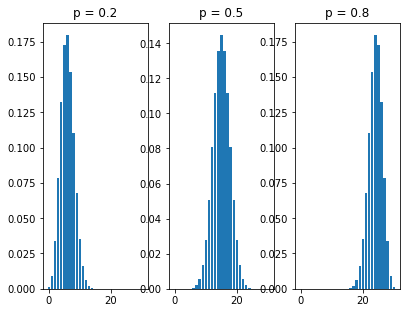

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
k = np.arange(31)
for i, p in enumerate([0.2, 0.5, 0.8], start=1):
    plt.subplot(1, 3, i)
    plt.bar(k, stats.binom.pmf(k, 30, p))
    plt.title(f'p = {p}')
plt.show()
```

</details>

#### Aufgabe 1.11

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import stats

print(f'{stats.binom.pmf(0, 3, 0.5):.4f}')
print(stats.binom.cdf(3, 3, 0.5))
print(stats.binom.mean(3, 0.5))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
0.1250
1.0
1.5
```

- Keine Treffer bei 3 Münzwürfen: `0.5 · 0.5 · 0.5 = 0.125`, mit 4 Nachkommastellen `0.1250`.
- Mehr als 3 Treffer gibt es bei 3 Versuchen nicht, also ist „höchstens 3“ sicher: `1.0`.
- Erwartungswert `n · p = 3 · 0.5 = 1.5`.

</details>

#### Aufgabe 1.12

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import stats

n, p = 10, 0.5
print(f'{stats.binom.cdf(4, n, p) + stats.binom.sf(4, n, p):.4f}')
print(f'{stats.binom.pmf(3, n, p) - stats.binom.pmf(7, n, p):.4f}')

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
1.0000
0.0000
```

- `cdf(4)` ist `P(X ≤ 4)`, `sf(4)` ist `P(X > 4)`. Zusammen ist das alles, also `1.0000`.
- Bei `p = 0.5` ist die Verteilung symmetrisch: 3 Treffer sind genauso wahrscheinlich wie 3 Nieten, also 7 Treffer. Die Differenz ist `0.0000`.

</details>

## 2. Ziehen ohne Zurücklegen und Warten auf den ersten Treffer

#### Hypergeometrische Verteilung: `stats.hypergeom`

Zieht man **ohne Zurücklegen**, ändert sich die Trefferwahrscheinlichkeit bei jedem Zug. Die Anzahl der Treffer ist dann **hypergeometrisch verteilt**.
`stats.hypergeom.pmf(k, M, n, N)` ist die Wahrscheinlichkeit für `k` Treffer, wenn

- `M` die Anzahl **aller** Kugeln ist,
- `n` die Anzahl der **Treffer-Kugeln** darunter,
- `N` die Anzahl der **gezogenen** Kugeln.

Achtung: Das `n` hat hier eine andere Bedeutung als bei der Binomialverteilung. `cdf`, `sf`, `mean` und `std` gibt es genauso.

Beispiel Lotto 6 aus 49: 49 Kugeln, 6 davon hat man angekreuzt, 6 werden gezogen.

In [ ]:
import numpy as np
from scipy import stats

print(f'{stats.hypergeom.pmf(3, 49, 6, 6):.6f}')
print(stats.hypergeom.pmf(6, 49, 6, 6))
print(np.round(stats.hypergeom.pmf(np.arange(7), 49, 6, 6), 6))

#### Binomialkoeffizient: `special.comb()`

Die Wahrscheinlichkeiten der beiden Verteilungen enthalten den **Binomialkoeffizienten** „n über k“: die Anzahl der Möglichkeiten,
`k` Dinge aus `n` auszuwählen. Im Modul `scipy.special` berechnet ihn `special.comb(n, k, exact=True)` als ganze Zahl
(ohne `exact=True` als Kommazahl). `special.perm(n, k, exact=True)` zählt die Möglichkeiten, wenn die **Reihenfolge** zählt.

In [ ]:
from scipy import special

print(special.comb(49, 6, exact=True))
print(special.comb(5, 2, exact=True), special.perm(5, 2, exact=True))
print(special.comb(6, 3, exact=True) * special.comb(43, 3, exact=True) / special.comb(49, 6, exact=True))

#### Warten auf den ersten Treffer: `stats.geom`

Wie oft muss man würfeln, bis die erste Sechs fällt? Die Anzahl `X` der Versuche bis einschließlich zum ersten Treffer ist **geometrisch verteilt**.
`stats.geom.pmf(k, p)` ist die Wahrscheinlichkeit, dass der erste Treffer genau im `k`-ten Versuch kommt: `(1 - p)^(k-1) · p`.
Der Erwartungswert ist `1 / p`.

In [ ]:
from scipy import stats

p = 1 / 6
print(f'{stats.geom.pmf(1, p):.4f} {stats.geom.pmf(3, p):.4f}')
print(f'{stats.geom.cdf(6, p):.4f}')
print(f'{stats.geom.mean(p):.4f}')

#### Aufgabe 2.1

Gib die Wahrscheinlichkeiten für 4 und für 5 Richtige im Lotto 6 aus 49 aus (8 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.00096862
0.00001845
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
print(f'{stats.hypergeom.pmf(4, 49, 6, 6):.8f}')
print(f'{stats.hypergeom.pmf(5, 49, 6, 6):.8f}')
```

</details>

#### Aufgabe 2.2

In einer Klasse mit 28 Personen haben 10 ihre Hausaufgaben nicht gemacht. Es werden 5 zufällig ausgewählt.
Gib die Wahrscheinlichkeit aus, dass keine, genau 2 und mindestens 3 davon ihre Hausaufgaben nicht gemacht haben (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.0872
0.3736
0.2278
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
print(f'{stats.hypergeom.pmf(0, 28, 10, 5):.4f}')
print(f'{stats.hypergeom.pmf(2, 28, 10, 5):.4f}')
print(f'{stats.hypergeom.sf(2, 28, 10, 5):.4f}')
```

</details>

#### Aufgabe 2.3

Vergleiche Ziehen mit und ohne Zurücklegen: In einer Urne sind 20 Kugeln, 8 davon rot. Es werden 5 gezogen.
Gib für `k` von 0 bis 5 die Wahrscheinlichkeiten für `k` rote Kugeln aus, einmal hypergeometrisch und einmal binomial mit `p = 8/20` (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0 0.0511 0.0778
1 0.2554 0.2592
2 0.3973 0.3456
3 0.2384 0.2304
4 0.0542 0.0768
5 0.0036 0.0102
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
for k in range(6):
    print(f'{k} {stats.hypergeom.pmf(k, 20, 8, 5):.4f} {stats.binom.pmf(k, 5, 8 / 20):.4f}')
```

</details>

#### Aufgabe 2.4

Je mehr Kugeln in der Urne sind, desto weniger macht das Zurücklegen aus. Gib für 2 rote Kugeln unter 5 gezogenen die hypergeometrische
Wahrscheinlichkeit bei 20, 200 und 2000 Kugeln (40 % rot) und zum Vergleich die binomiale aus (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
20 0.3973
200 0.3500
2000 0.3460
0.3456
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
for M in [20, 200, 2000]:
    print(f'{M} {stats.hypergeom.pmf(2, M, M * 4 // 10, 5):.4f}')
print(f'{stats.binom.pmf(2, 5, 0.4):.4f}')
```

</details>

#### Aufgabe 2.5

Berechne die Wahrscheinlichkeit für 3 Richtige im Lotto selbst mit `special.comb()`: (6 über 3) · (43 über 3) / (49 über 6).
Vergleiche mit `stats.hypergeom` (8 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.01765040
0.01765040
```

In [ ]:
from scipy import special, stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import special, stats
w = special.comb(6, 3, exact=True) * special.comb(43, 3, exact=True) / special.comb(49, 6, exact=True)
print(f'{w:.8f}')
print(f'{stats.hypergeom.pmf(3, 49, 6, 6):.8f}')
```

</details>

#### Aufgabe 2.6

Auf wie viele Arten kann man aus 12 Personen ein Team aus 4 Personen auswählen? Und auf wie viele Arten Platz 1 bis 4 eines Wettbewerbs vergeben?

**Erwartete Ausgabe:**
```
495
11880
```

In [ ]:
from scipy import special
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import special
print(special.comb(12, 4, exact=True))
print(special.perm(12, 4, exact=True))
```

</details>

#### Aufgabe 2.7

Bei einem Glücksrad gewinnt man mit Wahrscheinlichkeit 0.15. Gib die Wahrscheinlichkeit aus, dass der erste Gewinn genau beim 5. Drehen kommt,
dass man höchstens 5-mal drehen muss und wie oft man im Mittel drehen muss (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.0783
0.5563
6.6667
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
p = 0.15
print(f'{stats.geom.pmf(5, p):.4f}')
print(f'{stats.geom.cdf(5, p):.4f}')
print(f'{stats.geom.mean(p):.4f}')
```

</details>

#### Aufgabe 2.8

Mensch ärgere dich nicht: Man darf erst starten, wenn man eine Sechs würfelt. Wie oft muss man würfeln können, damit man mit mindestens 95 %
Wahrscheinlichkeit eine Sechs hatte? Benutze eine Schleife mit `stats.geom.cdf()`.

**Erwartete Ausgabe:**
```
17
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
k = 1
while stats.geom.cdf(k, 1 / 6) < 0.95:
    k += 1
print(k)
```

</details>

#### Aufgabe 2.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import stats

print(stats.hypergeom.pmf(2, 2, 2, 2))
print(stats.hypergeom.mean(10, 5, 4))
print(f'{stats.geom.pmf(1, 0.25):.2f}')

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
1.0
2.0
0.25
```

- 2 Kugeln, beide sind Treffer, beide werden gezogen: Man zieht sicher 2 Treffer, `1.0`.
- Die Hälfte der 10 Kugeln sind Treffer, gezogen werden 4: im Mittel `4 · 5/10 = 2.0` Treffer.
- Der erste Versuch ist gleich ein Treffer mit der Wahrscheinlichkeit `p = 0.25`.

</details>

## 3. Die Normalverteilung

#### `stats.norm`

Viele Messgrößen (Körpergrößen, Abfüllmengen, Messfehler) sind ungefähr **normalverteilt**: Die Werte häufen sich um den Mittelwert `μ`
und werden nach außen symmetrisch seltener (die **Gaußsche Glockenkurve**). `μ` heißt bei scipy `loc`, die Standardabweichung `σ` heißt `scale`.

| Aufruf | Bedeutung |
|---|---|
| `stats.norm.pdf(x, mu, sigma)` | Wert der Glockenkurve (Dichte) an der Stelle `x` |
| `stats.norm.cdf(x, mu, sigma)` | `P(X ≤ x)` |
| `stats.norm.sf(x, mu, sigma)` | `P(X > x)` |
| `stats.norm.ppf(q, mu, sigma)` | die Grenze `x`, unter der der Anteil `q` liegt (Umkehrung von `cdf`, *percent point function*) |

Bei einer stetigen Verteilung ist `P(X = x)` immer 0. Man fragt deshalb nach Bereichen. „Kleiner als“ und „höchstens“ sind hier dasselbe.

In [ ]:
from scipy import stats

mu, sigma = 175, 7      # Körpergröße in cm
print(f'{stats.norm.cdf(180, mu, sigma):.4f}')
print(f'{stats.norm.sf(190, mu, sigma):.4f}')
print(f'{stats.norm.cdf(180, mu, sigma) - stats.norm.cdf(170, mu, sigma):.4f}')
print(f'{stats.norm.ppf(0.9, mu, sigma):.2f}')

#### Die Sigma-Regeln und die Glockenkurve

Unabhängig von `μ` und `σ` liegen etwa 68.3 % der Werte im Bereich `μ ± σ`, 95.4 % in `μ ± 2σ` und 99.7 % in `μ ± 3σ`.
Ohne Angabe von `mu` und `sigma` rechnet scipy mit der **Standardnormalverteilung** (`μ = 0`, `σ = 1`).

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

for k in [1, 2, 3]:
    print(f'{k} {stats.norm.cdf(k) - stats.norm.cdf(-k):.4f}')
x = np.linspace(-4, 4, 200)
plt.plot(x, stats.norm.pdf(x))
plt.show()

#### Aufgabe 3.1

Eine Maschine füllt Müslipackungen. Die Füllmenge ist normalverteilt mit `μ = 500 g` und `σ = 4 g`.
Gib die Anteile der Packungen aus, die weniger als 495 g, mehr als 510 g und zwischen 496 g und 504 g enthalten (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.1056
0.0062
0.6827
```

In [ ]:
from scipy import stats

mu, sigma = 500, 4    # Abfüllmenge in g
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats

mu, sigma = 500, 4    # Abfüllmenge in g
print(f'{stats.norm.cdf(495, mu, sigma):.4f}')
print(f'{stats.norm.sf(510, mu, sigma):.4f}')
print(f'{stats.norm.cdf(504, mu, sigma) - stats.norm.cdf(496, mu, sigma):.4f}')
```

</details>

#### Aufgabe 3.2

Welche Füllmenge wird von den 5 % leichtesten Packungen unterschritten, welche von den 1 % schwersten überschritten? Gib die Grenzen auf
zwei Nachkommastellen aus.

**Erwartete Ausgabe:**
```
493.42
509.31
```

In [ ]:
from scipy import stats

mu, sigma = 500, 4    # Abfüllmenge in g
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats

mu, sigma = 500, 4    # Abfüllmenge in g
print(f'{stats.norm.ppf(0.05, mu, sigma):.2f}')
print(f'{stats.norm.ppf(0.99, mu, sigma):.2f}')
```

</details>

#### Aufgabe 3.3

In welchem zum Mittelwert symmetrischen Bereich liegen 90 % aller Füllmengen? Gib die beiden Grenzen auf zwei Nachkommastellen aus.

**Erwartete Ausgabe:**
```
493.42 506.58
```

In [ ]:
from scipy import stats

mu, sigma = 500, 4    # Abfüllmenge in g
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats

mu, sigma = 500, 4    # Abfüllmenge in g
print(f'{stats.norm.ppf(0.05, mu, sigma):.2f} {stats.norm.ppf(0.95, mu, sigma):.2f}')
```

</details>

#### Aufgabe 3.4

Prüfe die Sigma-Regeln für die Füllmengen: Gib für `k` = 1, 2, 3 die Grenzen `μ - kσ` und `μ + kσ` und den Anteil dazwischen aus (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
1 496 504 0.6827
2 492 508 0.9545
3 488 512 0.9973
```

In [ ]:
from scipy import stats

mu, sigma = 500, 4    # Abfüllmenge in g
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats

mu, sigma = 500, 4    # Abfüllmenge in g
for k in [1, 2, 3]:
    a, b = mu - k * sigma, mu + k * sigma
    print(f'{k} {a} {b} {stats.norm.cdf(b, mu, sigma) - stats.norm.cdf(a, mu, sigma):.4f}')
```

</details>

#### Aufgabe 3.5

Auf welchen Mittelwert `μ` muss die Maschine eingestellt werden (bei `σ = 4`), damit nur 3 % der Packungen weniger als 495 g enthalten?
Löse `cdf(495, μ, 4) = 0.03` mit `optimize.brentq()` im Intervall von 495 bis 520 und vergleiche mit `495 - 4 · ppf(0.03)` (zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
502.52
502.52
```

In [ ]:
from scipy import stats, optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats, optimize

def h(mu):
    return stats.norm.cdf(495, mu, 4) - 0.03

print(f'{optimize.brentq(h, 495, 520):.2f}')
print(f'{495 - 4 * stats.norm.ppf(0.03):.2f}')
```

</details>

#### Aufgabe 3.6

Die Ergebnisse eines Tests sind normalverteilt mit `μ = 62` und `σ = 12` Punkten. Die besten 15 % bekommen eine Eins.
Ab wie vielen Punkten gibt es eine Eins (ganze Punkte, aufgerundet mit `np.ceil()`)? Wie viel Prozent haben weniger als 40 Punkte (eine Nachkommastelle)?

**Erwartete Ausgabe:**
```
75.0
3.3
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
print(np.ceil(stats.norm.ppf(0.85, 62, 12)))
print(f'{stats.norm.cdf(40, 62, 12) * 100:.1f}')
```

</details>

#### Aufgabe 3.7

Für große `n` ist die Binomialverteilung ungefähr normalverteilt mit `μ = np` und `σ = √(np(1-p))`.
Vergleiche für `n = 200`, `p = 0.3` die Wahrscheinlichkeit `P(X ≤ 55)` mit der Binomialverteilung, mit der Normalverteilung an der Stelle 55
und an der Stelle 55.5 (**Stetigkeitskorrektur**). 4 Nachkommastellen.

**Erwartete Ausgabe:**
```
0.2455
0.2202
0.2437
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
n, p = 200, 0.3
mu = n * p
sigma = np.sqrt(n * p * (1 - p))
print(f'{stats.binom.cdf(55, n, p):.4f}')
print(f'{stats.norm.cdf(55, mu, sigma):.4f}')
print(f'{stats.norm.cdf(55.5, mu, sigma):.4f}')
```

</details>

#### Aufgabe 3.8

Zeichne die Glockenkurve der Füllmengen für x von 485 bis 515 (300 Punkte) und färbe die Fläche zwischen 496 und 504 hellblau
(`plt.fill_between(x2, stats.norm.pdf(x2, mu, sigma), color='lightblue')` mit 100 Punkten `x2`). Der Titel ist der Anteil in Prozent mit einer Nachkommastelle,
z. B. `68.3 %`.

**Erwartete Ausgabe:**

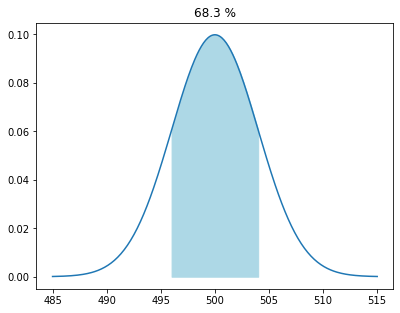

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

mu, sigma = 500, 4
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

mu, sigma = 500, 4
x = np.linspace(485, 515, 300)
x2 = np.linspace(496, 504, 100)
anteil = stats.norm.cdf(504, mu, sigma) - stats.norm.cdf(496, mu, sigma)
plt.plot(x, stats.norm.pdf(x, mu, sigma))
plt.fill_between(x2, stats.norm.pdf(x2, mu, sigma), color='lightblue')
plt.title(f'{anteil * 100:.1f} %')
plt.show()
```

</details>

#### Aufgabe 3.9

Zeichne die Binomialverteilung mit `n = 50` und `p = 0.4` als Säulendiagramm und darüber die Glockenkurve der Normalverteilung mit
demselben `μ` und `σ` als rote Linie (x von 5 bis 35, 200 Punkte). Zeige nur den Bereich von 5 bis 35 (`plt.xlim(5, 35)`).

**Erwartete Ausgabe:**

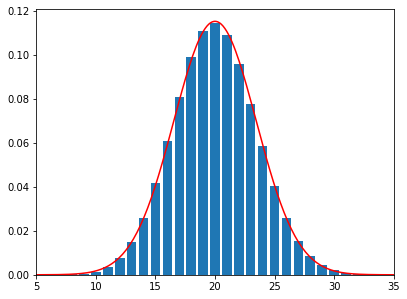

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
n, p = 50, 0.4
k = np.arange(n + 1)
plt.bar(k, stats.binom.pmf(k, n, p))
x = np.linspace(5, 35, 200)
plt.plot(x, stats.norm.pdf(x, n * p, np.sqrt(n * p * (1 - p))), color='red')
plt.xlim(5, 35)
plt.show()
```

</details>

#### Aufgabe 3.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import stats

print(stats.norm.cdf(0))
print(f'{stats.norm.cdf(100, 100, 15):.2f}')
print(stats.norm.ppf(0.5, 20, 3))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
0.5
0.50
20.0
```

Die Glockenkurve ist symmetrisch zum Mittelwert, deshalb liegt genau die Hälfte der Werte darunter:
- Standardnormalverteilung, Mittelwert 0: `0.5`.
- Mittelwert 100, Grenze 100: `0.50` (mit 2 Nachkommastellen ausgegeben).
- `ppf(0.5)` ist die Grenze, unter der die Hälfte liegt: der Mittelwert `20.0`.

</details>

## 4. Zufallszahlen aus Verteilungen

#### `rvs()` und `describe()`

Jede Verteilung in `scipy.stats` kann Zufallszahlen erzeugen: `stats.binom.rvs(n, p, size=..., random_state=rng)`
(*random variates*). Für `random_state` gibt man einen Zufallsgenerator `rng = np.random.default_rng(seed)` an
(wie in *numpy: Zufall und Statistik*). Mit festem Seed kommen bei jedem Lauf dieselben Zahlen heraus.

`stats.describe(daten)` berechnet mehrere Kennzahlen auf einmal: `nobs` (Anzahl), `minmax` (Tupel aus Minimum und Maximum), `mean`, `variance`
(die **Stichprobenvarianz**, bei der durch `n - 1` geteilt wird, anders als bei `np.var()`).

In [ ]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(1)
wuerfe = stats.binom.rvs(10, 1 / 6, size=8, random_state=rng)
print(wuerfe)
groessen = stats.norm.rvs(175, 7, size=1000, random_state=rng)
d = stats.describe(groessen)
print(f'{d.nobs} {d.minmax[0]:.1f} {d.minmax[1]:.1f}')
print(f'{d.mean:.2f} {d.variance:.2f} {np.var(groessen):.2f}')

#### Aufgabe 4.1

Simuliere mit `rng = np.random.default_rng(3)` 20-mal das Werfen von 50 Münzen (`stats.binom.rvs(50, 0.5, size=20, random_state=rng)`)
und gib die Anzahlen von Kopf aus, danach ihren Mittelwert.

**Erwartete Ausgabe:**
```
[20 22 28 26 20 24 25 21 27 21 24 25 24 26 27 31 23 26 27 23]
24.5
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
rng = np.random.default_rng(3)
kopf = stats.binom.rvs(50, 0.5, size=20, random_state=rng)
print(kopf)
print(kopf.mean())
```

</details>

#### Aufgabe 4.2

Simuliere mit Seed 5 10000-mal die Anzahl der Sechsen bei 12 Würfen. Vergleiche die relativen Häufigkeiten für 0 bis 5 Sechsen
(`np.bincount()`) mit den Wahrscheinlichkeiten der Binomialverteilung (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0 0.1158 0.1122
1 0.2682 0.2692
2 0.2964 0.2961
3 0.1946 0.1974
4 0.0893 0.0888
5 0.0278 0.0284
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
rng = np.random.default_rng(5)
sechsen = stats.binom.rvs(12, 1 / 6, size=10000, random_state=rng)
h = np.bincount(sechsen) / 10000
for k in range(6):
    print(f'{k} {h[k]:.4f} {stats.binom.pmf(k, 12, 1 / 6):.4f}')
```

</details>

#### Aufgabe 4.3

Erzeuge mit Seed 8 500 normalverteilte Füllmengen (`μ = 500`, `σ = 4`). Gib mit `describe()` Anzahl, Minimum, Maximum, Mittelwert und
Standardabweichung (Wurzel aus `variance`) aus, alles auf zwei Nachkommastellen.

**Erwartete Ausgabe:**
```
500
487.40 512.94
500.06 4.06
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
rng = np.random.default_rng(8)
menge = stats.norm.rvs(500, 4, size=500, random_state=rng)
d = stats.describe(menge)
print(d.nobs)
print(f'{d.minmax[0]:.2f} {d.minmax[1]:.2f}')
print(f'{d.mean:.2f} {np.sqrt(d.variance):.2f}')
```

</details>

#### Aufgabe 4.4

Welcher Anteil der 500 simulierten Füllmengen aus der vorigen Aufgabe liegt im Bereich `μ ± σ` (496 bis 504)? Vergleiche mit der Sigma-Regel
(4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.6760
0.6827
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
rng = np.random.default_rng(8)
menge = stats.norm.rvs(500, 4, size=500, random_state=rng)
print(f'{((menge >= 496) & (menge <= 504)).mean():.4f}')
print(f'{stats.norm.cdf(1) - stats.norm.cdf(-1):.4f}')
```

</details>

#### Aufgabe 4.5

Zeichne ein Histogramm (`plt.hist(daten, bins=30, density=True)`) von 2000 normalverteilten Körpergrößen (`μ = 175`, `σ = 7`, Seed 2)
und darüber die Glockenkurve als rote Linie (x von 150 bis 200, 200 Punkte). `density=True` skaliert die Säulen so, dass sie zur Kurve passen.

**Erwartete Ausgabe:**

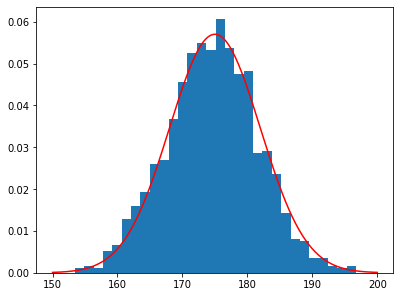

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
rng = np.random.default_rng(2)
groessen = stats.norm.rvs(175, 7, size=2000, random_state=rng)
plt.hist(groessen, bins=30, density=True)
x = np.linspace(150, 200, 200)
plt.plot(x, stats.norm.pdf(x, 175, 7), color='red')
plt.show()
```

</details>

#### Aufgabe 4.6

Simuliere 1000-mal (Seed 4) die Wartezeit bis zur ersten Sechs (`stats.geom.rvs(1/6, size=1000, random_state=rng)`). Gib die mittlere Wartezeit
(zwei Nachkommastellen) und die längste Wartezeit aus, und wie oft man länger als 20 Würfe warten musste.

**Erwartete Ausgabe:**
```
6.13 46
33
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
rng = np.random.default_rng(4)
warten = stats.geom.rvs(1 / 6, size=1000, random_state=rng)
print(f'{warten.mean():.2f} {warten.max()}')
print((warten > 20).sum())
```

</details>

#### Aufgabe 4.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(0)
x = stats.binom.rvs(5, 1.0, size=4, random_state=rng)
print(x)
d = stats.describe(np.array([2, 4, 6]))
print(d.nobs, d.mean, d.variance)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
[5 5 5 5]
3 4.0 4.0
```

- Mit der Trefferwahrscheinlichkeit 1 ist jeder Versuch ein Treffer, also jedes Mal 5: `[5 5 5 5]`.
- `[2, 4, 6]` hat 3 Werte und den Mittelwert 4. Die Stichprobenvarianz ist `((2-4)² + 0² + (6-4)²) / (3 - 1) = 8 / 2 = 4`.

</details>

## 5. Hypothesentest mit der Binomialverteilung

#### Die Idee eines Hypothesentests

Ein Würfel soll gezinkt sein und zu oft eine Sechs zeigen. Man stellt die **Nullhypothese** `H0: p = 1/6` auf (der Würfel ist in Ordnung)
und würfelt `n = 120`-mal. Bei einem fairen Würfel erwartet man 20 Sechsen. Fallen **sehr viele** Sechsen, verwirft man `H0`.

Was „sehr viele“ heißt, legt das **Signifikanzniveau** `α` fest, meist 5 %: Der **Ablehnungsbereich** sind die großen Werte `k`, die bei einem
fairen Würfel zusammen höchstens mit 5 % Wahrscheinlichkeit vorkommen. Fällt das Ergebnis hinein, wird `H0` verworfen.
Dabei kann man sich irren: Verwirft man `H0`, obwohl der Würfel fair ist, ist das ein **Fehler 1. Art** (Wahrscheinlichkeit höchstens `α`).

Den Ablehnungsbereich `{g, ..., n}` findet man, indem man die kleinste Grenze `g` mit `P(X ≥ g) ≤ α` sucht, also `sf(g - 1) ≤ α`.

In [ ]:
import numpy as np
from scipy import stats

n, p, alpha = 120, 1 / 6, 0.05
k = np.arange(n + 1)
mindestens = stats.binom.sf(k - 1, n, p)     # P(X >= k) für alle k
g = k[mindestens <= alpha].min()
print('Ablehnungsbereich ab', g)
print(f'Fehler 1. Art: {stats.binom.sf(g - 1, n, p):.4f}')

#### Der p-Wert: `stats.binomtest()`

Statt den Ablehnungsbereich zu bestimmen, kann man auch fragen: Wie wahrscheinlich ist bei gültiger Nullhypothese ein Ergebnis, das **mindestens so extrem**
ist wie das beobachtete? Das ist der **p-Wert**. Ist er kleiner als `α`, wird `H0` verworfen. Beide Wege führen zur selben Entscheidung.

`stats.binomtest(k, n, p, alternative=...)` berechnet den p-Wert (Attribut `pvalue`). `alternative` gibt die Richtung der Gegenhypothese an:

| `alternative` | Gegenhypothese | p-Wert |
|---|---|---|
| `'greater'` | `p` ist größer (rechtsseitiger Test) | `P(X ≥ k)` |
| `'less'` | `p` ist kleiner (linksseitiger Test) | `P(X ≤ k)` |
| `'two-sided'` | `p` ist anders (zweiseitiger Test, Standard) | beide Seiten |

In [ ]:
from scipy import stats

ergebnis = stats.binomtest(29, 120, 1 / 6, alternative='greater')
print(f'{ergebnis.pvalue:.4f}')
print(f'{stats.binom.sf(28, 120, 1 / 6):.4f}')
print(ergebnis.pvalue < 0.05)

#### Aufgabe 5.1

Bestimme für den Würfeltest aus dem Beispiel den Ablehnungsbereich bei einem Signifikanzniveau von 1 % und die Wahrscheinlichkeit für den Fehler 1. Art.

**Erwartete Ausgabe:**
```
Ablehnungsbereich ab 31
Fehler 1. Art: 0.0071
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
n, p, alpha = 120, 1 / 6, 0.01
k = np.arange(n + 1)
g = k[stats.binom.sf(k - 1, n, p) <= alpha].min()
print('Ablehnungsbereich ab', g)
print(f'Fehler 1. Art: {stats.binom.sf(g - 1, n, p):.4f}')
```

</details>

#### Aufgabe 5.2

Ein Hersteller behauptet, dass höchstens 10 % seiner Bauteile defekt sind (`H0: p = 0.1`). Ein Kunde vermutet mehr und prüft 80 Bauteile.
Bestimme den Ablehnungsbereich zum Niveau 5 % und entscheide für 13 defekte Bauteile. Gib die Grenze und die Entscheidung (`H0 verwerfen` oder
`H0 nicht verwerfen`) aus.

**Erwartete Ausgabe:**
```
14
H0 nicht verwerfen
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
n, p, alpha = 80, 0.1, 0.05
k = np.arange(n + 1)
g = k[stats.binom.sf(k - 1, n, p) <= alpha].min()
print(g)
if 13 >= g:
    print('H0 verwerfen')
else:
    print('H0 nicht verwerfen')
```

</details>

#### Aufgabe 5.3

Eine Partei hatte bei der letzten Wahl 30 %. Sie befürchtet, dass ihr Anteil gesunken ist. In einer Umfrage unter 200 Personen wollen sie 48 wählen.
Bestimme für den linksseitigen Test (`H0: p = 0.3`, `α = 0.05`) die größte Grenze `g` mit `P(X ≤ g) ≤ α` und den p-Wert mit `binomtest()` (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
Ablehnungsbereich bis 48
0.0359
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
n, p, alpha = 200, 0.3, 0.05
k = np.arange(n + 1)
g = k[stats.binom.cdf(k, n, p) <= alpha].max()
print('Ablehnungsbereich bis', g)
print(f"{stats.binomtest(48, n, p, alternative='less').pvalue:.4f}")
```

</details>

#### Aufgabe 5.4

Eine Münze wird 100-mal geworfen und zeigt 61-mal Kopf. Ist sie unfair? Gib den p-Wert des zweiseitigen Tests (`H0: p = 0.5`) und
den des rechtsseitigen Tests aus (4 Nachkommastellen) und jeweils, ob bei `α = 0.05` verworfen wird.

**Erwartete Ausgabe:**
```
0.0352 True
0.0176 True
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
zwei = stats.binomtest(61, 100, 0.5).pvalue
rechts = stats.binomtest(61, 100, 0.5, alternative='greater').pvalue
print(f'{zwei:.4f} {zwei < 0.05}')
print(f'{rechts:.4f} {rechts < 0.05}')
```

</details>

#### Aufgabe 5.5

Ein neues Medikament soll besser wirken als das alte, das bei 60 % der Patienten hilft. Es hilft bei 37 von 50 Patienten.
Gib den p-Wert (rechtsseitig, 4 Nachkommastellen) und den Anteil der Patienten aus, bei denen es geholfen hat (`statistic`).

**Erwartete Ausgabe:**
```
0.0280
0.74
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
e = stats.binomtest(37, 50, 0.6, alternative='greater')
print(f'{e.pvalue:.4f}')
print(e.statistic)
```

</details>

#### Aufgabe 5.6

**Fehler 2. Art:** Der Würfel aus dem Beispiel ist in Wirklichkeit gezinkt und zeigt die Sechs mit `p = 0.25`. Mit welcher Wahrscheinlichkeit
fällt das Ergebnis trotzdem **nicht** in den Ablehnungsbereich (ab 28), sodass man `H0` fälschlich beibehält? Gib sie für `p` = 0.2, 0.25 und 0.3 aus
(4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.2 0.7902
0.25 0.3036
0.3 0.0425
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
for p in [0.2, 0.25, 0.3]:
    print(f'{p} {stats.binom.cdf(27, 120, p):.4f}')
```

</details>

#### Aufgabe 5.7

Wie viele Würfe braucht man mindestens, damit ein Würfel mit `p = 0.25` für die Sechs mit mindestens 90 % Wahrscheinlichkeit erkannt wird
(Fehler 2. Art höchstens 10 %, Test zum Niveau 5 %)? Bestimme für `n` = 50, 60, 70, ... (bis höchstens 500) jeweils den Ablehnungsbereich und den
Fehler 2. Art und gib das erste `n`, die Grenze und den Fehler 2. Art (4 Nachkommastellen) aus.

**Erwartete Ausgabe:**
```
210 45 0.0995
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
for n in range(50, 501, 10):
    k = np.arange(n + 1)
    g = k[stats.binom.sf(k - 1, n, 1 / 6) <= 0.05].min()
    beta = stats.binom.cdf(g - 1, n, 0.25)
    if beta <= 0.1:
        print(f'{n} {g} {beta:.4f}')
        break
```

</details>

#### Aufgabe 5.8

Zeichne die Verteilung der Anzahl der Sechsen bei 120 Würfen eines fairen Würfels als Säulendiagramm (k von 0 bis 45).
Färbe die Säulen im Ablehnungsbereich (ab 28) rot und die übrigen grau (zwei Aufrufe von `plt.bar()`).

**Erwartete Ausgabe:**

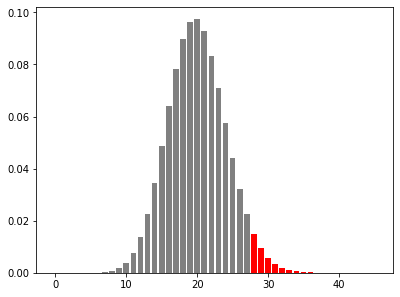

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
k = np.arange(46)
w = stats.binom.pmf(k, 120, 1 / 6)
plt.bar(k[k < 28], w[k < 28], color='gray')
plt.bar(k[k >= 28], w[k >= 28], color='red')
plt.show()
```

</details>

#### Aufgabe 5.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import stats

e = stats.binomtest(10, 10, 0.5, alternative='greater')
print(e.pvalue)
print(e.statistic)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
0.0009765625
1.0
```

- Der p-Wert ist `P(X ≥ 10)` bei 10 Münzwürfen, also die Wahrscheinlichkeit für 10-mal Kopf: `0.5^10 = 0.0009765625`.
- `statistic` ist der beobachtete Anteil `10 / 10 = 1.0`.

</details>

## 6. Mittelwerte vergleichen: der t-Test

#### Einstichproben-t-Test: `stats.ttest_1samp()`

Eine Abfüllmaschine soll im Mittel 500 g abfüllen. Eine Stichprobe von 12 Packungen hat einen Mittelwert von 498.9 g. Ist die Maschine falsch eingestellt,
oder ist die Abweichung nur Zufall? Weil man `σ` nicht kennt, sondern nur aus der Stichprobe schätzt, nimmt man den **t-Test**.

`stats.ttest_1samp(daten, mu0)` prüft die Nullhypothese „der Mittelwert ist `mu0`“. Das Ergebnis hat die Attribute `statistic`
(die Testgröße `t`: wie viele geschätzte Standardfehler der Stichprobenmittelwert von `mu0` entfernt ist) und `pvalue`.
Ist `pvalue < α`, wird die Nullhypothese verworfen. Wie bei `binomtest()` gibt es `alternative='less'` und `'greater'`.

Der t-Test setzt voraus, dass die Werte ungefähr normalverteilt sind.

In [ ]:
import numpy as np
from scipy import stats

menge = np.array([498.2, 501.0, 497.5, 499.8, 496.9, 500.4, 498.0, 497.2, 501.3, 499.1, 498.6, 497.8])
print(f'{menge.mean():.2f}')
e = stats.ttest_1samp(menge, 500)
print(f'{e.statistic:.4f} {e.pvalue:.4f}')
print(e.pvalue < 0.05)

#### Zwei Gruppen vergleichen: `ttest_ind()` und `ttest_rel()`

- `stats.ttest_ind(a, b)` vergleicht die Mittelwerte zweier **unabhängiger** Gruppen (z. B. zwei Klassen, zwei Sorten).
  Mit `equal_var=False` wird nicht vorausgesetzt, dass beide Gruppen gleich stark streuen (*Welch-Test*); das ist meist die sicherere Wahl.
- `stats.ttest_rel(vorher, nachher)` vergleicht **verbundene** Stichproben: dieselben Personen zweimal gemessen.
  Er testet, ob die Differenzen im Mittel 0 sind.

In [ ]:
import numpy as np
from scipy import stats

sorte_a = np.array([31.2, 29.8, 33.5, 30.9, 32.4, 28.7, 31.8, 30.5])
sorte_b = np.array([28.4, 27.9, 30.1, 26.8, 29.5, 28.2, 27.3, 29.0])
e = stats.ttest_ind(sorte_a, sorte_b, equal_var=False)
print(f'{e.statistic:.4f} {e.pvalue:.6f}')

vorher = np.array([312, 285, 298, 330, 276, 305])
nachher = np.array([298, 280, 290, 315, 279, 292])
e = stats.ttest_rel(vorher, nachher)
print(f'{e.statistic:.4f} {e.pvalue:.4f}')

#### Aufgabe 6.1

Eine Bäckerei verkauft Brötchen mit angeblich 60 g. Prüfe mit dem Einstichproben-t-Test (zweiseitig) die Stichprobe. Gib Mittelwert (zwei Nachkommastellen),
`t` und p-Wert (4 Nachkommastellen) und die Entscheidung bei `α = 0.05` (`True`, wenn verworfen) aus.

**Erwartete Ausgabe:**
```
58.96
-4.3003 0.0020
True
```

In [ ]:
import numpy as np
from scipy import stats

broetchen = np.array([58.4, 59.1, 60.2, 57.9, 58.8, 59.5, 58.1, 60.0, 58.6, 59.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

broetchen = np.array([58.4, 59.1, 60.2, 57.9, 58.8, 59.5, 58.1, 60.0, 58.6, 59.0])
print(f'{broetchen.mean():.2f}')
e = stats.ttest_1samp(broetchen, 60)
print(f'{e.statistic:.4f} {e.pvalue:.4f}')
print(e.pvalue < 0.05)
```

</details>

#### Aufgabe 6.2

Die Bäckerei interessiert vor allem, ob die Brötchen zu **leicht** sind. Führe den linksseitigen Test (`alternative='less'`) durch und gib den p-Wert aus
(4 Nachkommastellen). Er ist halb so groß wie der zweiseitige.

**Erwartete Ausgabe:**
```
0.0010
```

In [ ]:
import numpy as np
from scipy import stats

broetchen = np.array([58.4, 59.1, 60.2, 57.9, 58.8, 59.5, 58.1, 60.0, 58.6, 59.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

broetchen = np.array([58.4, 59.1, 60.2, 57.9, 58.8, 59.5, 58.1, 60.0, 58.6, 59.0])
e = stats.ttest_1samp(broetchen, 60, alternative='less')
print(f'{e.pvalue:.4f}')
```

</details>

#### Aufgabe 6.3

Zwei Klassen haben denselben Test geschrieben. Vergleiche die Punktzahlen mit `ttest_ind(..., equal_var=False)`. Gib beide Mittelwerte
(eine Nachkommastelle), den p-Wert (4 Nachkommastellen) und die Entscheidung bei `α = 0.05` aus.

**Erwartete Ausgabe:**
```
36.6 32.8
0.0902
False
```

In [ ]:
import numpy as np
from scipy import stats

klasse_a = np.array([34, 41, 28, 45, 38, 30, 42, 36, 39, 33, 44, 29])
klasse_b = np.array([31, 36, 27, 40, 35, 29, 33, 38, 30, 34, 28])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

klasse_a = np.array([34, 41, 28, 45, 38, 30, 42, 36, 39, 33, 44, 29])
klasse_b = np.array([31, 36, 27, 40, 35, 29, 33, 38, 30, 34, 28])
print(f'{klasse_a.mean():.1f} {klasse_b.mean():.1f}')
p = stats.ttest_ind(klasse_a, klasse_b, equal_var=False).pvalue
print(f'{p:.4f}')
print(p < 0.05)
```

</details>

#### Aufgabe 6.4

Zehn Personen machen ein Konzentrationstraining. Vor und nach dem Training wird die Zeit (in s) für eine Aufgabe gemessen.
Hat das Training die Zeit verkürzt? Gib die mittlere Differenz `vorher - nachher` (zwei Nachkommastellen) und den p-Wert des einseitigen Tests
`ttest_rel(vorher, nachher, alternative='greater')` (4 Nachkommastellen) aus.

**Erwartete Ausgabe:**
```
1.89
0.0004
```

In [ ]:
import numpy as np
from scipy import stats

vorher = np.array([48.2, 52.1, 45.6, 50.3, 47.8, 55.0, 49.4, 51.2, 46.9, 53.5])
nachher = np.array([45.9, 50.8, 45.1, 47.2, 46.0, 52.4, 49.8, 48.5, 45.3, 50.1])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

vorher = np.array([48.2, 52.1, 45.6, 50.3, 47.8, 55.0, 49.4, 51.2, 46.9, 53.5])
nachher = np.array([45.9, 50.8, 45.1, 47.2, 46.0, 52.4, 49.8, 48.5, 45.3, 50.1])
print(f'{(vorher - nachher).mean():.2f}')
print(f"{stats.ttest_rel(vorher, nachher, alternative='greater').pvalue:.4f}")
```

</details>

#### Aufgabe 6.5

Zeige, dass `ttest_rel(vorher, nachher)` dasselbe Ergebnis liefert wie `ttest_1samp(vorher - nachher, 0)`: Gib für beide `t` und p-Wert aus (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
5.0335 0.0007
5.0335 0.0007
```

In [ ]:
import numpy as np
from scipy import stats

vorher = np.array([48.2, 52.1, 45.6, 50.3, 47.8, 55.0, 49.4, 51.2, 46.9, 53.5])
nachher = np.array([45.9, 50.8, 45.1, 47.2, 46.0, 52.4, 49.8, 48.5, 45.3, 50.1])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

vorher = np.array([48.2, 52.1, 45.6, 50.3, 47.8, 55.0, 49.4, 51.2, 46.9, 53.5])
nachher = np.array([45.9, 50.8, 45.1, 47.2, 46.0, 52.4, 49.8, 48.5, 45.3, 50.1])
a = stats.ttest_rel(vorher, nachher)
b = stats.ttest_1samp(vorher - nachher, 0)
print(f'{a.statistic:.4f} {a.pvalue:.4f}')
print(f'{b.statistic:.4f} {b.pvalue:.4f}')
```

</details>

#### Aufgabe 6.6

Je größer die Stichprobe, desto eher wird ein kleiner Unterschied erkannt. Erzeuge mit Seed 6 Stichproben der Größe 10, 50 und 250 aus einer Normalverteilung
mit `μ = 501` und `σ = 4` und teste jeweils gegen `mu0 = 500` (zweiseitig). Gib Größe und p-Wert (4 Nachkommastellen) aus. Benutze für alle drei denselben `rng`.

**Erwartete Ausgabe:**
```
10 0.0706
50 0.0273
250 0.0001
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
rng = np.random.default_rng(6)
for n in [10, 50, 250]:
    daten = stats.norm.rvs(501, 4, size=n, random_state=rng)
    print(f'{n} {stats.ttest_1samp(daten, 500).pvalue:.4f}')
```

</details>

#### Aufgabe 6.7

Zeichne die Punktzahlen der beiden Klassen als Boxplot nebeneinander (`plt.boxplot([klasse_a, klasse_b])`) und schreibe den p-Wert des
t-Tests mit 3 Nachkommastellen als Titel (z. B. `p = 0.123`).

**Erwartete Ausgabe:**

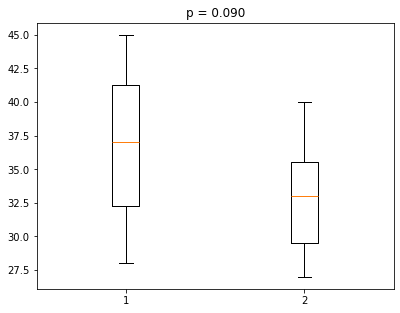

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

klasse_a = np.array([34, 41, 28, 45, 38, 30, 42, 36, 39, 33, 44, 29])
klasse_b = np.array([31, 36, 27, 40, 35, 29, 33, 38, 30, 34, 28])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

klasse_a = np.array([34, 41, 28, 45, 38, 30, 42, 36, 39, 33, 44, 29])
klasse_b = np.array([31, 36, 27, 40, 35, 29, 33, 38, 30, 34, 28])
p = stats.ttest_ind(klasse_a, klasse_b, equal_var=False).pvalue
plt.boxplot([klasse_a, klasse_b])
plt.title(f'p = {p:.3f}')
plt.show()
```

</details>

#### Aufgabe 6.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import stats

daten = np.array([9, 10, 11, 10])
e = stats.ttest_1samp(daten, 10)
print(e.statistic, e.pvalue)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
0.0 1.0
```

Der Mittelwert der Daten ist genau 10, also genau der Wert der Nullhypothese. Die Testgröße `t` (Abstand zum Mittelwert in Standardfehlern) ist `0.0`.
Ein Ergebnis, das mindestens so extrem ist, kommt immer vor: Der p-Wert ist `1.0`.

</details>

## 7. Häufigkeiten vergleichen: der Chi-Quadrat-Test

#### Anpassungstest: `stats.chisquare()`

Ein Würfel wird 120-mal geworfen. Passen die beobachteten Häufigkeiten der Augenzahlen zu einem fairen Würfel (je 20 erwartet)?
Der **Chi-Quadrat-Test** misst die Abweichung mit der Testgröße

`χ² = Σ (beobachtet - erwartet)² / erwartet`.

Je größer `χ²`, desto schlechter passen die Beobachtungen. `stats.chisquare(beobachtet, erwartet)` berechnet `statistic` (`χ²`) und `pvalue`.
Ohne `erwartet` wird Gleichverteilung angenommen. Die erwarteten Häufigkeiten müssen dieselbe Summe haben wie die beobachteten und sollten mindestens 5 sein.

In [ ]:
import numpy as np
from scipy import stats

beobachtet = np.array([16, 22, 19, 25, 14, 24])
e = stats.chisquare(beobachtet)
print(f'{e.statistic:.4f} {e.pvalue:.4f}')
erwartet = np.full(6, 20)
print(f'{((beobachtet - erwartet) ** 2 / erwartet).sum():.4f}')

#### Unabhängigkeitstest: `stats.chi2_contingency()`

Hängen zwei Merkmale zusammen, z. B. die Altersgruppe und das bevorzugte Verkehrsmittel? Die Beobachtungen stehen in einer **Kreuztabelle**
(Zeilen: Ausprägungen des einen Merkmals, Spalten: des anderen). `stats.chi2_contingency(tabelle)` testet die Nullhypothese
„die Merkmale sind unabhängig“ und liefert:

- `statistic` und `pvalue` wie oben,
- `dof`: die Anzahl der **Freiheitsgrade** `(Zeilen - 1) · (Spalten - 1)`,
- `expected_freq`: die bei Unabhängigkeit erwarteten Häufigkeiten (Zeilensumme · Spaltensumme / Gesamtzahl).

Bei einer 2×2-Tabelle verwendet scipy eine Korrektur (nach Yates), die `χ²` etwas kleiner macht. Mit `correction=False` rechnet es ohne.

In [ ]:
import numpy as np
from scipy import stats

#                     Fahrrad  Bus  Auto
tabelle = np.array([[45,      30,   5],     # unter 18
                    [25,      20,  35],     # 18 bis 40
                    [10,      15,  45]])    # über 40
e = stats.chi2_contingency(tabelle)
print(f'{e.statistic:.4f} {e.pvalue < 0.05} {e.dof}')
print(np.round(e.expected_freq, 2))

#### Aufgabe 7.1

Ein Würfel wurde 300-mal geworfen. Prüfe mit `chisquare()`, ob er fair ist. Gib `χ²` und den p-Wert (4 Nachkommastellen) und die Entscheidung
bei `α = 0.05` aus.

**Erwartete Ausgabe:**
```
3.8800 0.5668
False
```

In [ ]:
import numpy as np
from scipy import stats

augen = np.array([41, 55, 48, 46, 52, 58])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

augen = np.array([41, 55, 48, 46, 52, 58])
e = stats.chisquare(augen)
print(f'{e.statistic:.4f} {e.pvalue:.4f}')
print(e.pvalue < 0.05)
```

</details>

#### Aufgabe 7.2

Berechne `χ²` für denselben Würfel selbst nach der Formel und vergleiche (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
3.8800
3.8800
```

In [ ]:
import numpy as np
from scipy import stats

augen = np.array([41, 55, 48, 46, 52, 58])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

augen = np.array([41, 55, 48, 46, 52, 58])
erwartet = np.full(6, augen.sum() / 6)
print(f'{((augen - erwartet) ** 2 / erwartet).sum():.4f}')
print(f'{stats.chisquare(augen).statistic:.4f}')
```

</details>

#### Aufgabe 7.3

Bei Erbsen erwartet man nach den Mendelschen Regeln die vier Sorten im Verhältnis 9 : 3 : 3 : 1. Gezählt wurden die Anzahlen unten.
Berechne die erwarteten Anzahlen (zwei Nachkommastellen) und teste mit `chisquare(beobachtet, erwartet)`. Gib `χ²` und p-Wert aus (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
[312.75 104.25 104.25  34.75]
0.4700 0.9254
```

In [ ]:
import numpy as np
from scipy import stats

beobachtet = np.array([315, 108, 101, 32])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

beobachtet = np.array([315, 108, 101, 32])
anteile = np.array([9, 3, 3, 1]) / 16
erwartet = anteile * beobachtet.sum()
print(np.round(erwartet, 2))
e = stats.chisquare(beobachtet, erwartet)
print(f'{e.statistic:.4f} {e.pvalue:.4f}')
```

</details>

#### Aufgabe 7.4

Ein Glücksrad hat vier Felder, die laut Hersteller mit den Wahrscheinlichkeiten 0.4, 0.3, 0.2 und 0.1 kommen. Bei 200 Drehungen wurde gezählt.
Gib den p-Wert (4 Nachkommastellen) und die Entscheidung bei `α = 0.05` aus.

**Erwartete Ausgabe:**
```
0.1406
False
```

In [ ]:
import numpy as np
from scipy import stats

gezaehlt = np.array([64, 70, 44, 22])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

gezaehlt = np.array([64, 70, 44, 22])
e = stats.chisquare(gezaehlt, np.array([0.4, 0.3, 0.2, 0.1]) * 200)
print(f'{e.pvalue:.4f}')
print(e.pvalue < 0.05)
```

</details>

#### Aufgabe 7.5

Gib für die Verkehrsmittel-Tabelle aus dem Beispiel `χ²`, Freiheitsgrade und die erwarteten Häufigkeiten aus (zwei Nachkommastellen).
Berechne die erwartete Häufigkeit für die erste Zelle zusätzlich selbst (Zeilensumme · Spaltensumme / Gesamtzahl).

**Erwartete Ausgabe:**
```
58.77 4
[[27.83 22.61 29.57]
 [27.83 22.61 29.57]
 [24.35 19.78 25.87]]
27.83
```

In [ ]:
import numpy as np
from scipy import stats

tabelle = np.array([[45, 30, 5], [25, 20, 35], [10, 15, 45]])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

tabelle = np.array([[45, 30, 5], [25, 20, 35], [10, 15, 45]])
e = stats.chi2_contingency(tabelle)
print(f'{e.statistic:.2f} {e.dof}')
print(np.round(e.expected_freq, 2))
print(f'{tabelle[0].sum() * tabelle[:, 0].sum() / tabelle.sum():.2f}')
```

</details>

#### Aufgabe 7.6

In einer Umfrage wurden Personen aus Stadt und Land nach ihrer Lieblingsjahreszeit gefragt. Prüfe, ob Wohnort und Lieblingsjahreszeit unabhängig sind.
Gib `χ²` (4 Nachkommastellen), Freiheitsgrade, p-Wert (4 Nachkommastellen) und die Entscheidung bei `α = 0.05` aus.

**Erwartete Ausgabe:**
```
3.3668 3 0.3384
False
```

In [ ]:
import numpy as np
from scipy import stats

#                    Frühling  Sommer  Herbst  Winter
tabelle = np.array([[38,       52,     24,     16],     # Stadt
                    [30,       40,     28,     22]])    # Land
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

#                    Frühling  Sommer  Herbst  Winter
tabelle = np.array([[38,       52,     24,     16],     # Stadt
                    [30,       40,     28,     22]])    # Land
e = stats.chi2_contingency(tabelle)
print(f'{e.statistic:.4f} {e.dof} {e.pvalue:.4f}')
print(e.pvalue < 0.05)
```

</details>

#### Aufgabe 7.7

Bei einer 2×2-Tabelle (Impfung ja/nein, erkrankt ja/nein) korrigiert scipy `χ²`. Gib `χ²` und p-Wert mit und ohne Korrektur (`correction=False`) aus
(4 Nachkommastellen).

**Erwartete Ausgabe:**
```
True 6.9570 0.0083
False 7.8538 0.0051
```

In [ ]:
import numpy as np
from scipy import stats

#                    erkrankt  nicht erkrankt
tabelle = np.array([[12,       188],      # geimpft
                    [29,       171]])     # nicht geimpft
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

#                    erkrankt  nicht erkrankt
tabelle = np.array([[12,       188],      # geimpft
                    [29,       171]])     # nicht geimpft
for korrektur in [True, False]:
    e = stats.chi2_contingency(tabelle, correction=korrektur)
    print(f'{korrektur} {e.statistic:.4f} {e.pvalue:.4f}')
```

</details>

#### Aufgabe 7.8

Simuliere mit Seed 9 einen fairen Würfel 600-mal (`rng.integers(1, 7, size=600)`), zähle die Augenzahlen mit `np.bincount(...)[1:]`
und teste auf Fairness. Gib die Häufigkeiten und den p-Wert aus (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
[ 95  98  84 115 109  99]
0.3141
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
rng = np.random.default_rng(9)
wuerfe = rng.integers(1, 7, size=600)
h = np.bincount(wuerfe)[1:]
print(h)
print(f'{stats.chisquare(h).pvalue:.4f}')
```

</details>

#### Aufgabe 7.9

Zeichne für den Würfel mit 300 Würfen die beobachteten Häufigkeiten als Säulen und die erwartete Häufigkeit 50 als rote waagerechte Linie
(`plt.axhline(50, color='red')`). Beschrifte die Säulen mit den Augenzahlen 1 bis 6 (`plt.bar(np.arange(1, 7), augen)`).

**Erwartete Ausgabe:**

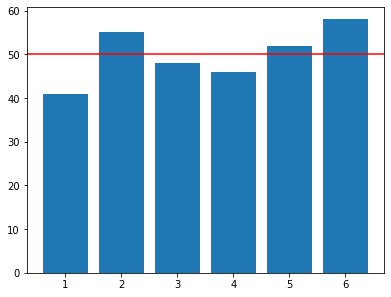

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

augen = np.array([41, 55, 48, 46, 52, 58])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

augen = np.array([41, 55, 48, 46, 52, 58])
plt.bar(np.arange(1, 7), augen)
plt.axhline(50, color='red')
plt.show()
```

</details>

#### Aufgabe 7.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import stats

e = stats.chisquare(np.array([10, 10, 10, 10]))
print(e.statistic, e.pvalue)
print(stats.chi2_contingency(np.array([[1, 2, 3], [4, 5, 6]])).dof)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
0.0 1.0
2
```

- Die Beobachtungen stimmen genau mit der Gleichverteilung überein (je 10). Alle Abweichungen sind 0, also `χ² = 0.0` und der p-Wert `1.0`.
- Eine Tabelle mit 2 Zeilen und 3 Spalten hat `(2 - 1) · (3 - 1) = 2` Freiheitsgrade.

</details>

## 8. Gemischte Übungen

#### Aufgabe 8.1

Eine Fluggesellschaft weiß, dass 8 % der Gebuchten nicht erscheinen. Ein Flugzeug hat 180 Plätze, es werden 190 Tickets verkauft.
Mit welcher Wahrscheinlichkeit erscheinen mehr als 180 Personen (4 Nachkommastellen)? Wie viele Tickets darf man höchstens verkaufen,
damit diese Wahrscheinlichkeit unter 5 % bleibt?

**Erwartete Ausgabe:**
```
0.0562
189
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
print(f'{stats.binom.sf(180, 190, 0.92):.4f}')
tickets = 180
while stats.binom.sf(180, tickets + 1, 0.92) < 0.05:
    tickets += 1
print(tickets)
```

</details>

#### Aufgabe 8.2

Eine Schule behauptet, dass 70 % der Schülerinnen und Schüler mit dem Fahrrad kommen. Bei einer Zählung unter 150 Personen waren es 93.
Führe einen zweiseitigen Binomialtest durch (p-Wert, 4 Nachkommastellen) und gib das 95-%-Vertrauensintervall für den Anteil aus
(`binomtest(...).proportion_ci()` liefert ein Objekt mit `low` und `high`, 4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.0400
0.5372 0.6979
```

In [ ]:
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats
e = stats.binomtest(93, 150, 0.7)
print(f'{e.pvalue:.4f}')
ci = e.proportion_ci()
print(f'{ci.low:.4f} {ci.high:.4f}')
```

</details>

#### Aufgabe 8.3

Ein Getränkeautomat füllt Becher mit `μ = 200 ml` und `σ = 6 ml`. Ein Becher fasst 210 ml. Wie viel Prozent der Becher laufen über (zwei Nachkommastellen)?
Wie klein muss `σ` werden, damit nur noch 0.5 % überlaufen? Löse mit `brentq()` im Intervall von 1 bis 6 (zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
4.78
3.88
```

In [ ]:
from scipy import stats, optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import stats, optimize
print(f'{stats.norm.sf(210, 200, 6) * 100:.2f}')

def h(sigma):
    return stats.norm.sf(210, 200, sigma) - 0.005

print(f'{optimize.brentq(h, 1, 6):.2f}')
```

</details>

#### Aufgabe 8.4

Drei Lernmethoden wurden ausprobiert. Für jede Methode ist gezählt, wie viele die Prüfung bestanden haben und wie viele nicht. Prüfe mit dem
Chi-Quadrat-Test, ob der Erfolg von der Methode abhängt (`χ²` und p-Wert auf 4 Nachkommastellen), und gib die Bestehensquote jeder Methode in Prozent aus
(eine Nachkommastelle).

**Erwartete Ausgabe:**
```
10.4387 0.0054
[70.  58.3 85. ]
```

In [ ]:
import numpy as np
from scipy import stats

#                    bestanden  nicht bestanden
tabelle = np.array([[42,        18],     # Methode A
                    [35,        25],     # Methode B
                    [51,         9]])    # Methode C
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

#                    bestanden  nicht bestanden
tabelle = np.array([[42,        18],     # Methode A
                    [35,        25],     # Methode B
                    [51,         9]])    # Methode C
e = stats.chi2_contingency(tabelle)
print(f'{e.statistic:.4f} {e.pvalue:.4f}')
print(np.round(tabelle[:, 0] / tabelle.sum(axis=1) * 100, 1))
```

</details>

#### Aufgabe 8.5

Ein Versuch mit Pflanzen: Die Wachstumshöhen (in cm) mit und ohne neuen Dünger sind gegeben. Gib die Mittelwerte (zwei Nachkommastellen) und
den p-Wert des einseitigen Welch-Tests aus, ob der Dünger das Wachstum erhöht (`alternative='greater'`, mit Dünger zuerst, 4 Nachkommastellen).

**Erwartete Ausgabe:**
```
25.71 23.79
0.0019
```

In [ ]:
import numpy as np
from scipy import stats

mit = np.array([24.1, 26.3, 23.8, 27.5, 25.2, 26.9, 24.7, 25.8, 27.1])
ohne = np.array([22.9, 24.5, 23.1, 25.0, 22.4, 24.8, 23.6, 24.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

mit = np.array([24.1, 26.3, 23.8, 27.5, 25.2, 26.9, 24.7, 25.8, 27.1])
ohne = np.array([22.9, 24.5, 23.1, 25.0, 22.4, 24.8, 23.6, 24.0])
print(f'{mit.mean():.2f} {ohne.mean():.2f}')
print(f"{stats.ttest_ind(mit, ohne, equal_var=False, alternative='greater').pvalue:.4f}")
```

</details>

#### Aufgabe 8.6

Simuliere den Fehler 1. Art: Erzeuge mit Seed 11 1000-mal eine Stichprobe von 20 Werten aus einer Normalverteilung mit `μ = 50`, `σ = 5` und teste jedes Mal
mit `ttest_1samp(..., 50)`. Gib den Anteil der Tests aus, bei denen `p < 0.05` herauskommt (obwohl die Nullhypothese stimmt). Er sollte etwa 0.05 sein.

**Erwartete Ausgabe:**
```
0.052
```

In [ ]:
import numpy as np
from scipy import stats
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats
rng = np.random.default_rng(11)
verworfen = 0
for i in range(1000):
    daten = stats.norm.rvs(50, 5, size=20, random_state=rng)
    if stats.ttest_1samp(daten, 50).pvalue < 0.05:
        verworfen += 1
print(verworfen / 1000)
```

</details>

#### Aufgabe 8.7

Denk dir selbst eine Fragestellung aus (z. B. „Würfeln Mädchen und Jungen gleich viele Sechsen?“, „Ist unser Klassenwürfel fair?“), sammle oder
erfinde Daten und entscheide mit einem passenden Test. Gib Nullhypothese, p-Wert und Entscheidung aus.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

klassenwuerfel = np.array([9, 12, 8, 11, 7, 13])
print('H0: Der Würfel ist fair.')
e = stats.chisquare(klassenwuerfel)
print(f'p-Wert: {e.pvalue:.4f}')
if e.pvalue < 0.05:
    print('verwerfen')
else:
    print('nicht verwerfen')
```

</details>